# 01 · Localización en el cielo y distancia: ¿coinciden la señal gravitacional y la contrapartida?

**Pregunta.** La señal de ondas gravitacionales **GW190521** (la fusión de dos agujeros negros más masiva detectada hasta 2020) viene acompañada de una posible señal de luz, la llamarada **ZTF19abanrhr**, observada por el telescopio ZTF. ¿Es plausible que ambas tengan el mismo origen?

**Cómo se responde.** Las ondas gravitacionales dan una *distribución de probabilidad* sobre dónde está la fuente (ascensión recta `ra`, declinación `dec` y distancia `dl`). Se compara, **en el punto exacto donde está la llamarada**, cuánta probabilidad asigna esa distribución *después* de medir la señal (el **posterior**) frente a cuánta asignaba *antes* de medir nada (el **prior**):

$$B = \frac{p(\text{punto ZTF}\mid\text{datos})}{\pi(\text{punto ZTF})}\qquad\text{(ratio de Savage-Dickey)}$$

* $B>1$: los datos hacen *más* probable la posición de la llamarada que antes de medir.
* $B\approx1$: los datos no dicen nada sobre esa posición.
* $B<1$: los datos la hacen *menos* probable.

**Detalle práctico.** Solo se dispone de *muestras* (nubes de puntos), no de funciones continuas. Por eso la densidad en un punto se estima con el **método de la caja**: se cuenta qué fracción de las muestras cae dentro de una caja pequeña centrada en el punto. El tamaño de la caja es delicado (muy pequeña → ruido; muy grande → se mezcla con regiones lejanas), así que se hace un **bootstrap** (remuestreo con reemplazo, 100 réplicas) y se busca el tamaño de caja donde el resultado se estabiliza (*plateau*).

**Qué hace este cuaderno.** Calcula $B$ para `ra`, para `dec`, para la distancia y para las combinaciones 2D (cielo) y 3D (cielo + distancia).

*Datos: muestras públicas de LIGO-Virgo para GW190521 (modelo de forma de onda NRSur7dq4), ver `data/README.md`.*

In [1]:
import sys
sys.path.insert(0, "../src")

import json
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt

import tfg_bayes as tb

tb.set_paper_style(font_size=12)
%matplotlib inline

## 1. Datos y punto de interés

Coordenadas de la contrapartida **ZTF19abanrhr** (Tabla 2 de la memoria). Los ángulos se convierten a radianes, que es la unidad de las muestras de LIGO-Virgo.

In [2]:
d = tb.load_gw190521()
ra_post, dec_post, dl_post = d["post_ra"], d["post_dec"], d["post_dl"]
ra_prior_ligo, dec_prior_ligo, dl_prior_ligo = d["prior_ra"], d["prior_dec"], d["prior_dl"]

ra_z, dec_z, dl_z = tb.RA_ZTF, tb.DEC_ZTF, tb.DL_ZTF

print(f"Muestras del posterior:                  {len(ra_post):,}")
print(f"Muestras del prior publicado por LIGO:   {len(ra_prior_ligo):,}")
print(f"ZTF19abanrhr:  ra = {ra_z:.5f} rad,  dec = {dec_z:.5f} rad,  dl = {dl_z} Mpc")

Muestras del posterior:                  65,723
Muestras del prior publicado por LIGO:   6,001
ZTF19abanrhr:  ra = 3.35847 rad,  dec = 0.60781 rad,  dl = 2443.1 Mpc


### El prior

El archivo de LIGO-Virgo solo trae **6 001 muestras de prior**: muy pocas para contar muestras dentro de cajas pequeñas. Como el prior es conocido (el que se usó en el análisis original), se **regenera** con más muestras:

* `ra`: uniforme entre 0 y 2π.
* `dec`: densidad proporcional a $\cos(\text{dec})$. Es lo que da un prior *isótropo*: cerca de los polos hay menos área de cielo por cada grado de declinación.
* `dl`: densidad proporcional a $d^2$. Es lo que da fuentes repartidas de forma homogénea en el volumen (el volumen de una cáscara esférica crece con $d^2$).

Se muestrean con el truco de la transformada inversa: `dec = arcsin(2u − 1)` y `dl = d_max · u^(1/3)` con `u` uniforme en [0, 1].

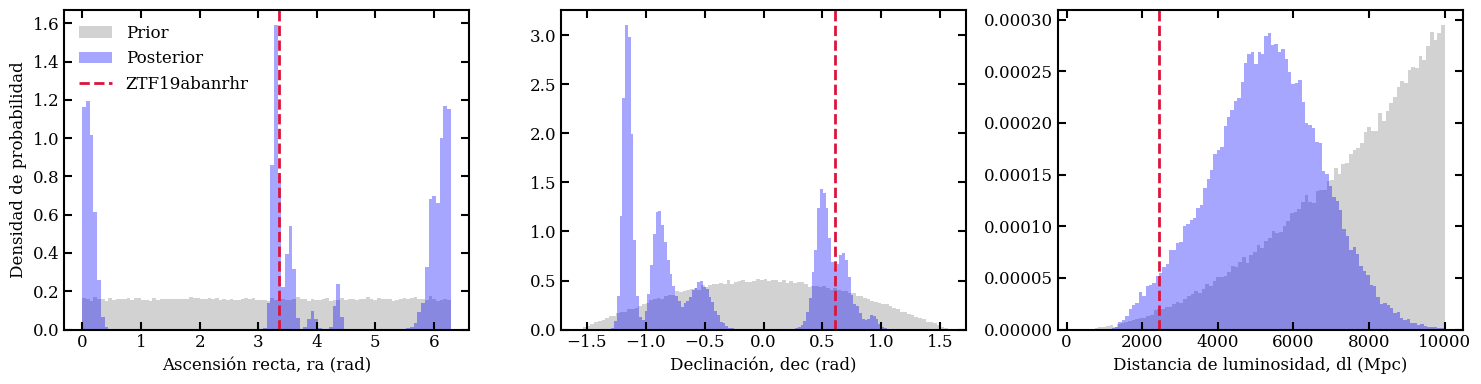

In [3]:
N_PRIOR = 100_000
ra_prior, dec_prior, dl_prior = tb.sample_sky_distance_prior(N_PRIOR, seed=1)

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, post, prior, z, xlabel in [
    (axes[0], ra_post, ra_prior, ra_z, "Ascensión recta, ra (rad)"),
    (axes[1], dec_post, dec_prior, dec_z, "Declinación, dec (rad)"),
    (axes[2], dl_post, dl_prior, dl_z, "Distancia de luminosidad, dl (Mpc)"),
]:
    ax.hist(prior, bins=100, density=True, histtype="stepfilled", color="gray", alpha=0.35, label="Prior")
    ax.hist(post, bins=100, density=True, histtype="stepfilled", color="blue", alpha=0.35, label="Posterior")
    ax.axvline(z, color="crimson", ls="--", lw=2, label="ZTF19abanrhr")
    ax.set_xlabel(xlabel)
axes[0].set_ylabel("Densidad de probabilidad")
axes[0].legend(frameon=False)
plt.tight_layout()
plt.show()

## 2. Factores de Bayes en una dimensión

Para cada coordenada se barre el tamaño de caja `L` y se calcula, en 100 réplicas bootstrap, el cociente `fracción de posterior en la caja / fracción de prior en la caja`. La línea es la mediana y la banda el intervalo del 90 %.

En los tres casos hay una zona central donde la curva es prácticamente plana (el *plateau*): ahí es donde se lee el factor de Bayes.

In [4]:
sizes_ra = np.logspace(-1.5, 0.3, 20)     # rad
sizes_dec = np.logspace(-1.5, 0.3, 20)    # rad
sizes_dl = np.logspace(1.0, 3.6, 20)      # Mpc

box1d = lambda x0: (lambda cols, L: tb.frac_in_box_1d_where(cols[0], x0, L))

P_ra = tb.bootstrap_ratio((ra_post,), (ra_prior,), box1d(ra_z), sizes_ra, seed=11)
P_dec = tb.bootstrap_ratio((dec_post,), (dec_prior,), box1d(dec_z), sizes_dec, seed=12)
P_dl = tb.bootstrap_ratio((dl_post,), (dl_prior,), box1d(dl_z), sizes_dl, seed=13)

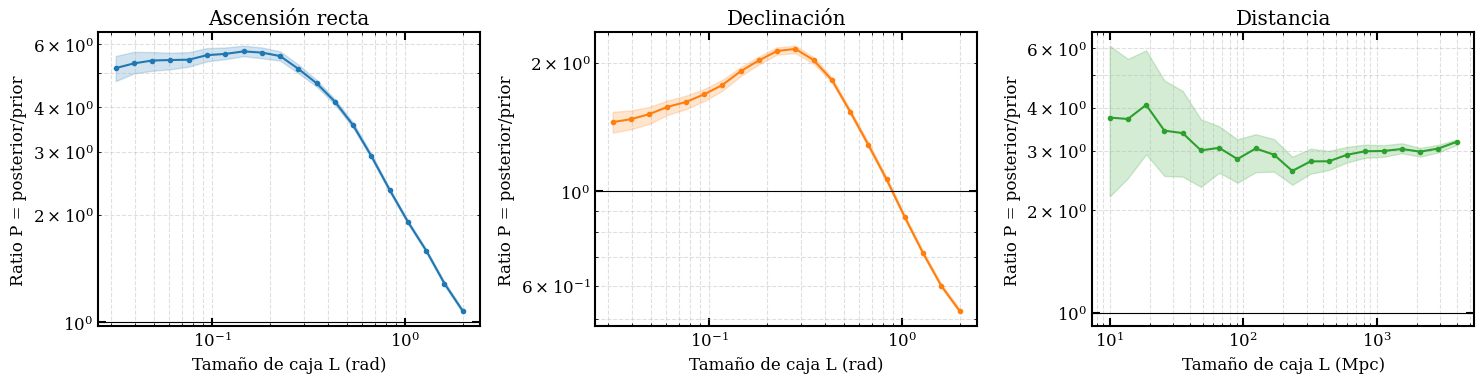

--- ra ---
     L (rad)    mediana            IC 90 %
      0.0489       5.41   [  5.06,   5.71]
      0.0941       5.60   [  5.38,   5.86]
       0.181       5.69   [  5.49,   5.88]
        0.28       5.13   [  4.98,   5.27]
       0.539       3.56   [  3.50,   3.63]
--- dec ---
     L (rad)    mediana            IC 90 %
      0.0489       1.52   [  1.44,   1.58]
      0.0941       1.69   [  1.63,   1.74]
       0.181       2.03   [  1.98,   2.07]
        0.28       2.16   [  2.11,   2.20]
       0.539       1.54   [  1.52,   1.56]
--- dl ---
     L (Mpc)    mediana            IC 90 %
        48.3       3.00   [  2.35,   3.70]
        90.8       2.83   [  2.41,   3.24]
         170       2.92   [  2.60,   3.24]
         439       2.79   [  2.63,   2.99]
         824       2.99   [  2.86,   3.12]


In [5]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
tb.plot_bootstrap(sizes_ra, P_ra, "Tamaño de caja L (rad)", ax=axes[0], color="C0")
tb.plot_bootstrap(sizes_dec, P_dec, "Tamaño de caja L (rad)", ax=axes[1], color="C1")
tb.plot_bootstrap(sizes_dl, P_dl, "Tamaño de caja L (Mpc)", ax=axes[2], color="C2")
for ax, t in zip(axes, ["Ascensión recta", "Declinación", "Distancia"]):
    ax.set_title(t)
    ax.axhline(1, color="k", lw=0.8)
plt.tight_layout()
plt.show()

def tabla(sizes, P, unidad, pick):
    med, lo, hi = tb.summarize(P)
    print(f"{'L (' + unidad + ')':>12}   {'mediana':>8}   {'IC 90 %':>16}")
    for L in pick:
        j = int(np.argmin(np.abs(sizes - L)))
        print(f"{sizes[j]:12.3g}   {med[j]:8.2f}   [{lo[j]:6.2f}, {hi[j]:6.2f}]")

print("--- ra ---");  tabla(sizes_ra, P_ra, "rad", [0.05, 0.1, 0.2, 0.3, 0.5])
print("--- dec ---"); tabla(sizes_dec, P_dec, "rad", [0.05, 0.1, 0.2, 0.3, 0.5])
print("--- dl ---");  tabla(sizes_dl, P_dl, "Mpc", [50, 100, 200, 400, 800])

## 3. Factor de Bayes del cielo (ra + dec)

`ra` y `dec` **no son independientes** en el posterior (la localización de una onda gravitacional forma una región alargada, a veces en arco), así que el factor conjunto no es el producto de los individuales. Se calcula con una caja bidimensional. En el bootstrap, `ra` y `dec` de cada muestra se remuestrean **juntas** (mismos índices) para conservar esa correlación.

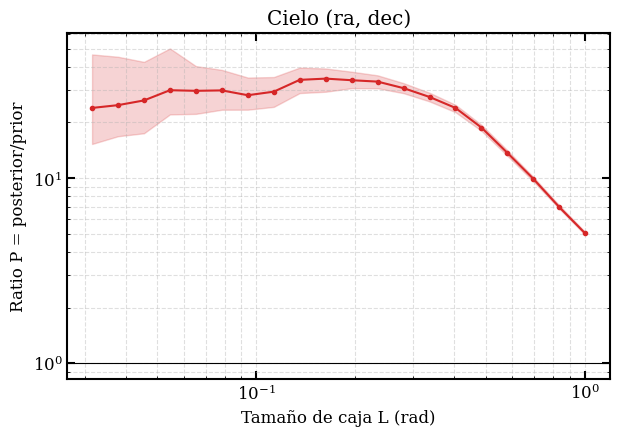

     L (rad)    mediana            IC 90 %
      0.0455      26.31   [ 17.49,  42.48]
      0.0941      28.07   [ 23.45,  34.96]
       0.162      34.50   [ 29.31,  39.13]
       0.195      33.82   [ 30.64,  37.60]
        0.28      30.65   [ 28.79,  32.62]
       0.336      27.47   [ 26.00,  28.95]
       0.483      18.78   [ 18.03,  19.42]


In [6]:
sizes_2d = np.logspace(-1.5, 0, 20)  # rad
box2d = lambda cols, L: tb.frac_in_box_2d_where(cols[0], cols[1], ra_z, dec_z, L)

P_2d = tb.bootstrap_ratio((ra_post, dec_post), (ra_prior, dec_prior), box2d, sizes_2d, seed=21)

fig, ax = plt.subplots(figsize=(7, 4.5))
tb.plot_bootstrap(sizes_2d, P_2d, "Tamaño de caja L (rad)", ax=ax, color="C3")
ax.axhline(1, color="k", lw=0.8)
ax.set_title("Cielo (ra, dec)")
plt.show()

tabla(sizes_2d, P_2d, "rad", [0.05, 0.1, 0.15, 0.2, 0.27, 0.35, 0.5])

## 4. Factor de Bayes del cielo + distancia (3D)

Aquí se añade la distancia a la caja. La caja es un prisma de lados `L_ang` (en `ra` y en `dec`) y `L_dl` (en distancia). Para barrer un único parámetro se escalan juntos: `L_dl = 1000 · L_ang` (con `L_ang` en rad y `L_dl` en Mpc), que incluye las dos cajas que cita la memoria (0,20 rad ↔ 200 Mpc y 0,15 rad ↔ 150 Mpc).

Con una caja 3D pequeña, el prior regenerado de 100 000 muestras casi no cae dentro (la probabilidad a priori de la caja es del orden de $10^{-5}$, es decir, **1–4 muestras**), así que el denominador del cociente es muy ruidoso. Por eso se calcula también con el **prior exacto**: la probabilidad a priori de la caja se obtiene con la fórmula analítica de los tres priors,

$$\pi(\text{caja}) = \frac{L_{ang}}{2\pi}\cdot\frac{\sin(\text{dec}_0+L_{ang}/2)-\sin(\text{dec}_0-L_{ang}/2)}{2}\cdot\frac{(d_0+L_{dl}/2)^3-(d_0-L_{dl}/2)^3}{d_{max}^3},$$

y solo el posterior se remuestrea.

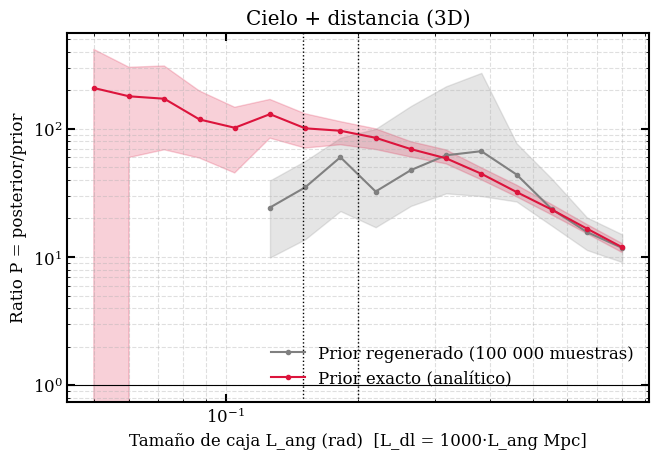

  L_ang    L_dl   prior·N |      prior regenerado      |        prior exacto       
  0.050      50       0.0 |     nan [   nan,    nan] |   208.1 [   0.0,  416.3]
  0.060      60       0.0 |     nan [   nan,    nan] |   179.3 [  59.8,  301.9]
  0.072      72       0.0 |     nan [   nan,    nan] |   171.7 [  68.7,  309.0]
  0.087      87       0.1 |     nan [   nan,    nan] |   118.3 [  59.2,  197.2]
  0.105     105       0.1 |     nan [   nan,    nan] |   101.9 [  45.3,  147.3]
  0.126     126       0.2 |    24.3 [   9.9,   39.6] |   130.1 [  84.6,  169.5]
  0.152     152       0.4 |    35.0 [  13.8,   56.2] |   100.9 [  70.8,  131.0]
  0.182     182       0.7 |    60.1 [  22.8,   85.1] |    96.6 [  75.2,  113.8]
  0.219     219       1.2 |    32.5 [  17.1,  100.0] |    85.1 [  69.0,  100.1]
  0.264     264       2.1 |    47.7 [  25.1,  150.6] |    69.5 [  60.2,   79.4]
  0.317     317       3.7 |    62.2 [  31.4,  214.6] |    58.9 [  53.4,   68.5]
  0.382     382       6.5 |    66.9 

In [7]:
sizes_ang = np.logspace(np.log10(0.05), np.log10(0.8), 16)   # rad
sizes_dl3 = 1000.0 * sizes_ang                               # Mpc

def box3d(cols, i):
    return tb.frac_in_box_3d_where(cols[0], cols[1], cols[2], ra_z, dec_z, dl_z,
                                   sizes_ang[i], sizes_ang[i], sizes_dl3[i])

idx = np.arange(len(sizes_ang))      # el "tamaño" que se barre es el índice de la caja

# (a) prior regenerado con 100 000 muestras (bootstrap de prior y posterior)
P_3d_samples = tb.bootstrap_ratio((ra_post, dec_post, dl_post), (ra_prior, dec_prior, dl_prior),
                                  box3d, idx, seed=31)
# (b) prior exacto (bootstrap solo del posterior)
f_prior_exact = np.array([tb.prior_prob_box_3d(a, l) for a, l in zip(sizes_ang, sizes_dl3)])
P_3d_exact = tb.bootstrap_ratio_exact_prior((ra_post, dec_post, dl_post), lambda i: f_prior_exact[i],
                                            box3d, idx, seed=32)

fig, ax = plt.subplots(figsize=(7.5, 4.8))
tb.plot_bootstrap(sizes_ang, P_3d_samples, "Tamaño de caja L_ang (rad)  [L_dl = 1000·L_ang Mpc]", ax=ax,
                  color="gray", label="Prior regenerado (100 000 muestras)")
tb.plot_bootstrap(sizes_ang, P_3d_exact, "Tamaño de caja L_ang (rad)  [L_dl = 1000·L_ang Mpc]", ax=ax,
                  color="crimson", label="Prior exacto (analítico)")
ax.axhline(1, color="k", lw=0.8)
ax.axvline(0.15, color="k", ls=":", lw=1); ax.axvline(0.20, color="k", ls=":", lw=1)
ax.legend(frameon=False)
ax.set_title("Cielo + distancia (3D)")
plt.show()

med_s, lo_s, hi_s = tb.summarize(P_3d_samples)
med_e, lo_e, hi_e = tb.summarize(P_3d_exact)
print(f"{'L_ang':>7} {'L_dl':>7} {'prior·N':>9} | {'prior regenerado':^26} | {'prior exacto':^26}")
for i in range(len(sizes_ang)):
    print(f"{sizes_ang[i]:7.3f} {sizes_dl3[i]:7.0f} {f_prior_exact[i]*N_PRIOR:9.1f} | "
          f"{med_s[i]:7.1f} [{lo_s[i]:6.1f},{hi_s[i]:7.1f}] | {med_e[i]:7.1f} [{lo_e[i]:6.1f},{hi_e[i]:7.1f}]")

### Cajas concretas de la memoria

Valores puntuales (sin bootstrap) para las cajas de la memoria, con el prior regenerado y con el prior exacto.

In [8]:
print(f"{'L_ang (rad)':>12} {'L_dl (Mpc)':>11} {'f_post':>10} {'f_prior (100k)':>15} {'P (100k)':>9} {'f_prior exacto':>15} {'P exacto':>9}")
for La, Ld in [(0.20, 200), (0.175, 175), (0.15, 150)]:
    f_post = tb.frac_in_box_3d_where(ra_post, dec_post, dl_post, ra_z, dec_z, dl_z, La, La, Ld)
    f_s = tb.frac_in_box_3d_where(ra_prior, dec_prior, dl_prior, ra_z, dec_z, dl_z, La, La, Ld)
    f_e = tb.prior_prob_box_3d(La, Ld)
    print(f"{La:12.3f} {Ld:11.0f} {f_post:10.2e} {f_s:15.2e} {tb.ratio(f_post, f_s):9.1f} {f_e:15.2e} {f_post/f_e:9.1f}")

 L_ang (rad)  L_dl (Mpc)     f_post  f_prior (100k)  P (100k)  f_prior exacto  P exacto
       0.200         200   8.37e-04        1.00e-05      83.7        9.35e-06      89.5
       0.175         175   6.09e-04        1.00e-05      60.9        6.26e-06      97.2
       0.150         150   4.26e-04        1.00e-05      42.6        3.95e-06     108.0


In [9]:
# Se guarda el resultado 3D recalculado para usarlo en el cuaderno 02 (combinación de factores)
Path("../results").mkdir(exist_ok=True)
resultado = {}
for La, Ld in [(0.20, 200), (0.15, 150)]:
    f_post = tb.frac_in_box_3d_where(ra_post, dec_post, dl_post, ra_z, dec_z, dl_z, La, La, Ld)
    resultado[f"B_sky_dl_L{La}rad_{Ld}Mpc"] = round(f_post / tb.prior_prob_box_3d(La, Ld), 1)
with open("../results/b_sky_distance.json", "w", encoding="utf-8") as f:
    json.dump(resultado, f, indent=2)
resultado

{'B_sky_dl_L0.2rad_200Mpc': 89.5, 'B_sky_dl_L0.15rad_150Mpc': 108.0}

## 5. Resumen

| Factor de Bayes | Tamaño de caja donde se lee | Recalculado aquí | Memoria |
|---|---|---|---|
| $B_{ra}$ | 0,1 – 0,2 rad | ≈ 5,5 | ≈ 5,5 |
| $B_{dec}$ | 0,2 – 0,3 rad | ≈ 2 | ≈ 2 |
| $B_{dl}$ | 50 – 800 Mpc (curva plana) | ≈ 3 | ≈ 3 |
| $B_{\Omega}$ (ra + dec) | 0,15 – 0,3 rad | ≈ 30 – 35 | ≈ 25 |
| $B_{\Omega,dl}$ (ra + dec + dl) | 0,15 – 0,20 rad y 150 – 200 Mpc | ≈ 90 – 110 | ≈ 30 |

**Los factores unidimensionales y el de cielo reproducen la memoria** (el de cielo sale algo mayor, 30–35 frente a 25, dentro de lo que cambian los valores según el prior y la caja elegidos).

**El factor 3D no reproduce el valor de la memoria (≈ 30).** Con las cajas citadas (0,15–0,20 rad y 150–200 Mpc) y el prior exacto sale ≈ 90–110, y con el prior regenerado de 100 000 muestras entre ≈ 40 y ≈ 85 (con 1 muestra de prior dentro de la caja, ver arriba). Dos observaciones ayudan a interpretar el resultado:

* **No hay un plateau claro en 3D.** Con el prior exacto el cociente decrece de forma continua al aumentar la caja (≈ 100 con 0,15 rad/150 Mpc, ≈ 45 con 0,38 rad/382 Mpc, ≈ 12 con 0,8 rad/800 Mpc). Un valor ≈ 30 solo aparece con cajas de ≈ 0,45 rad y ≈ 450 Mpc, o mayores, donde la caja ya no es "pequeña".
* **Es lo que cabría esperar a partir de los factores anteriores.** Si la distancia fuese casi independiente del cielo, $B_{\Omega,dl}\approx B_\Omega\cdot B_{dl}\approx 30\times3\approx 90$, que es justo lo que sale.

Esta diferencia no cambia la conclusión cualitativa (ver cuaderno 02), pero sí el número del factor combinado; se discute en el `README.md` del repositorio.